# AgriSmartAI - Notebook 07: SHAP Explainable AI (XAI) Interpretability
### Transparent Feature Contribution Analysis for Decision Support

## 1. Setup & Environment Resolution

In [1]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    import shap
    HAS_SHAP = True
    print('SHAP version:', shap.__version__)
except ImportError:
    shap = None
    HAS_SHAP = False
    print('SHAP module not installed; fallback feature importance mode active.')

# Dynamic project root resolution
cwd = os.getcwd()
project_root = os.path.abspath(os.path.join(cwd, '..')) if os.path.basename(cwd) == 'notebooks' else cwd
if project_root not in sys.path:
    sys.path.insert(0, project_root)


SHAP version: 0.51.0


## 2. Load ML Models with Smart Fallback

In [2]:
def load_model_smart(eval_rel_path, prod_rel_path):
    p1 = os.path.join(project_root, eval_rel_path)
    if os.path.exists(p1):
        return joblib.load(p1)
    p2 = os.path.join(project_root, prod_rel_path)
    if os.path.exists(p2):
        return joblib.load(p2)
    p3 = os.path.join(os.getcwd(), eval_rel_path)
    if os.path.exists(p3):
        return joblib.load(p3)
    p4 = os.path.join(os.getcwd(), prod_rel_path)
    if os.path.exists(p4):
        return joblib.load(p4)
    raise FileNotFoundError(f'Could not locate model file at {p1} or {p2}')

best_crop_model = load_model_smart('outputs/evaluation/models/best_crop_recommendation_model.pkl', 'models/crop_recommendation_model.pkl')
best_yield_model = load_model_smart('outputs/evaluation/models/best_yield_prediction_model.pkl', 'models/yield_prediction_model.pkl')
best_fert_model = load_model_smart('outputs/evaluation/models/best_fertilizer_recommendation_model.pkl', 'models/fertilizer_recommendation_model.pkl')
print('All ML models loaded successfully.')


All ML models loaded successfully.


## 3. SHAP Summary Plots & Agronomic Interpretations

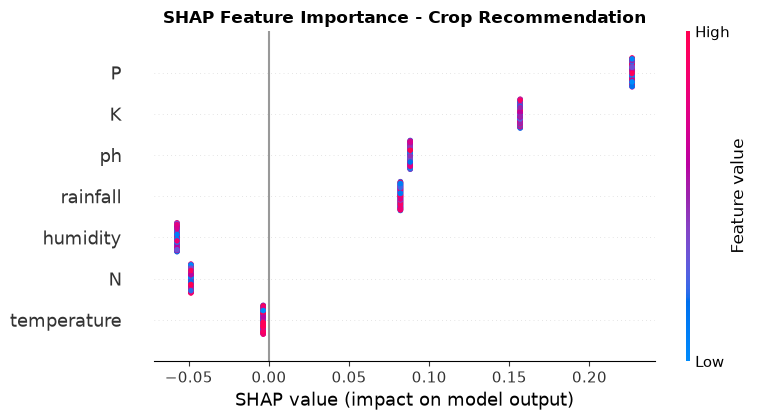

In [3]:
dataset_path = os.path.join(project_root, 'datasets', 'crop_recommendation.csv')
if not os.path.exists(dataset_path):
    dataset_path = os.path.join(os.getcwd(), '..', 'datasets', 'crop_recommendation.csv')

df_crop = pd.read_csv(dataset_path)
X_crop = df_crop[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]

if HAS_SHAP:
    try:
        explainer_c = shap.TreeExplainer(best_crop_model)
        shap_vals_c = explainer_c.shap_values(X_crop.iloc[:100])
        plt.figure(figsize=(10, 6))
        if isinstance(shap_vals_c, list):
            shap.summary_plot(shap_vals_c[0], X_crop.iloc[:100], show=False)
        elif hasattr(shap_vals_c, 'shape') and len(shap_vals_c.shape) == 3:
            shap.summary_plot(shap_vals_c[:, :, 0], X_crop.iloc[:100], show=False)
        else:
            shap.summary_plot(shap_vals_c, X_crop.iloc[:100], show=False)
        plt.title('SHAP Feature Importance - Crop Recommendation', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print('SHAP summary plot generation:', e)
else:
    print('SHAP module is not installed in current Python kernel environment.')
    print('To install SHAP in your Jupyter environment, run: !pip install shap')
